# Binary Search Trees

**Seong Cho** · ACME Volume 2, Lab 2

**Lab objective:** a tree is a linked list where each node may refer to more than one other node. After an overview of recursion, implement a recursively structured doubly linked Binary Search Tree, then compare the standard linked list, the Binary Search Tree, and an AVL tree to illustrate the relative strengths and weaknesses of each structure.

<sub>Lab specification from the *Volume 2* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
# trees.py
# """Volume 2: Trees.
# <Name>
# <Class>
# <Date>
# """

import random
import numpy as np
from matplotlib import pyplot as plt

## Recursion

A *recursive* function calls itself until it reaches a specified *base case* where the solution is known; it then exits without calling itself again, and each previous call is resolved. The sum of the positive integers from 1 to $n$ is recursive:

$$f(n) = \sum_{i=1}^{n} i = n + \sum_{i=1}^{n-1} i = n + f(n-1),$$

with base case $f(1) = 1$. Computing `recursive_sum(5)` calls `recursive_sum(4)`, which calls `recursive_sum(3)`, and so on down to the base case; substituting the returned values back up unwinds the recursion to 15.

In [2]:
def recursive_sum(n):
    """Calculate the sum of all positive integers in [1, n] recursively."""
    # Base Case: the sum of all positive integers in [1, 1] is 1.
    if n == 1:
        return 1
    # If the base case hasn't been reached, the function recurses by calling
    # itself on the next smallest integer. The result of that call, plus the
    # particular 'n' from this call, gives the result.
    else:
        return n + recursive_sum(n-1)

recursive_sum(5)

15

The Fibonacci numbers $g(n) = g(n-1) + g(n-2)$, $g(0) = 0$, $g(1) = 1$ are defined recursively, so a recursive implementation is natural. `recursive_fib()` calls itself twice at each step, so its calls branch into a tree: `recursive_fib(5)` reaches the base cases 8 times, and the sum of their results, $1 + 0 + 1 + 1 + 0 + 1 + 0 + 1 = 5$, is the answer. The key to recursion is understanding the base cases correctly and making correct recursive calls.

In [3]:
def iterative_fib(n):
    """Calculate the nth Fibonacci number iteratively."""
    fibonacci = []                  # Initialize an empty list.
    fibonacci.append(0)             # Append 0 (the 0th Fibonacci number).
    fibonacci.append(1)             # Append 1 (the 1st Fibonacci number).
    for i in range(1, n):
        # Starting at the third entry, calculate the next number
        # by adding the last two entries in the list.
        fibonacci.append(fibonacci[-1] + fibonacci[-2])
    # When the entire list has been loaded, return the nth entry.
    return fibonacci[n]

def recursive_fib(n):
    """Calculate the nth Fibonacci number recursively."""
    # The base cases are the first two Fibonacci numbers.
    if n == 0:                      # Base case 1: the 0th Fibonacci number is 0.
        return 0
    elif n == 1:                    # Base case 2: the 1st Fibonacci number is 1.
        return 1
    # If this call isn't a base case, the function recurses by calling
    # itself to calculate the previous two Fibonacci numbers.
    else:
        return recursive_fib(n-1) + recursive_fib(n-2)

print([recursive_fib(n) for n in range(12)])
assert all(iterative_fib(n) == recursive_fib(n) for n in range(20))

[0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89]


## Problem 1: Recursive search

> **Problem 1.** The following code defines a simple class for singly linked lists. *(The `SinglyLinkedListNode` and `SinglyLinkedList` classes are in the first code cell below.)* Rewrite the following iterative function for finding data in a linked list using recursion. Use instances of the `SinglyLinkedList` class to test your function.
>
> ```python
> def iterative_search(linkedlist, data):
>     """Search 'linkedlist' iteratively for a node containing 'data'."""
>     current = linkedlist.head
>     while current is not None:
>         if current.value == data:
>             return current
>         current = current.next
>     raise ValueError(str(data) + " is not in the list.")
> ```
>
> (Hint: define a second function to perform the actual recursion.)

In [4]:
class SinglyLinkedListNode:
    """Simple singly linked list node."""
    def __init__(self, data):
        self.value, self.next = data, None

class SinglyLinkedList:
    """A very simple singly linked list with a head and a tail."""
    def __init__(self):
        self.head, self.tail = None, None

    def append(self, data):
        """Add a Node containing 'data' to the end of the list."""
        n = SinglyLinkedListNode(data)
        if self.head is None:
            self.head, self.tail = n, n
        else:
            self.tail.next = n
            self.tail = n

def iterative_search(linkedlist, data):
    """Search 'linkedlist' iteratively for a node containing 'data'.
    If there is no such node in the list, or if the list is empty,
    raise a ValueError.

    Inputs:
        linkedlist (SinglyLinkedList): a linked list.
        data: the data to search for in the list.

    Returns:
        The node in 'linkedlist' containing 'data'.
    """
    current = linkedlist.head
    while current is not None:
        if current.value == data:
            return current
        current = current.next
    raise ValueError(str(data) + " is not in the list.")

In [5]:
# Problem 1
def recursive_search(linkedlist, data):
    """Search 'linkedlist' recursively for a node containing 'data'.
    If there is no such node in the list, or if the list is empty,
    raise a ValueError.

    Inputs:
        linkedlist (SinglyLinkedList): a linked list object.
        data: the data to search for in the list.

    Returns:
        The node in 'linkedlist' containing 'data'.
    """
    temp = linkedlist.head
    end = linkedlist.tail
    if linkedlist.head == None:
        raise ValueError(str(data) + " is not in the list.")
    def search_recursion(node, data, end_node):
        if node.value == data:
            return node
        elif node == end_node:
            raise ValueError(str(data) + " is not in the list.")
        else:
            return search_recursion(node.next, data, end_node)
    return search_recursion(temp, data, end)

In [6]:
def make_sll(items):
    s = SinglyLinkedList()
    for x in items:
        s.append(x)
    return s

words = make_sll(["apple", "banana", "cherry", "date"])
for w in ["apple", "cherry", "date"]:            # head, middle, tail
    node = recursive_search(words, w)
    assert node is iterative_search(words, w)
    print(w, "->", type(node).__name__, node.value)

one = make_sll([42])
assert recursive_search(one, 42) is one.head

nums = make_sll(range(500))
assert all(recursive_search(nums, i).value == i for i in range(500))

for lst, target in [(words, "fig"), (one, 7), (SinglyLinkedList(), 1)]:
    try:
        recursive_search(lst, target)
    except ValueError as e:
        print(f"recursive_search(..., {target!r}) -> ValueError: {e}")
    else:
        raise AssertionError("recursive_search() should raise ValueError")

apple -> SinglyLinkedListNode apple
cherry -> SinglyLinkedListNode cherry
date -> SinglyLinkedListNode date
recursive_search(..., 'fig') -> ValueError: fig is not in the list.
recursive_search(..., 7) -> ValueError: 7 is not in the list.
recursive_search(..., 1) -> ValueError: 1 is not in the list.


> **Achtung!** It is not usually better to rewrite an iterative method recursively. In Python, a function may only call itself 999 times. On the 1000th call, a `RuntimeError` is raised to prevent a stack overflow. Whether or not recursion is appropriate depends on the problem to be solved and the algorithm used to solve it.

## Trees

A *tree* is a specialized linked list. Trees are harder to build than standard linked lists but almost always more efficient: finding a node in a linked list is $O(n)$, while a well-built, balanced tree finds a node in $O(\log n)$. The first node is the *root*; it points to *children*, each child points to its own children, and a node with no children is a *leaf*. Mathematically a tree is a directed graph with no cycles, so a linked list is a (boring) tree: the head is the root, each node has one child, and the last node is the only leaf.

## Binary Search Trees

In a *binary search tree* (BST) each node has up to two children, `left` and `right`. The left child contains data less than its parent's data, and the right child's data is greater. In practice BST nodes keep track of their data, their children, and (in doubly linked trees) their parent. `find()` works recursively: starting at the root, if the data does not match the current node, search the left child if the data is smaller and the right child if it is larger, until the data is found or an empty child is reached.

> **Note.** Conceptually, each node of a BST partitions the data of its subtree into two halves: the data that is less than the parent, and the data that is greater. We will extend this concept to higher dimensions in the next lab.

To insert new data, add a leaf node at the correct location: find (recursively, like `find()`) the node that should be the new node's parent, then attach the new node as that parent's left or right child.

## Problem 2: insert()

> **Problem 2.** Implement the `insert()` method in the `BST` class.
>
> 1. Find the parent of the new node. Consider writing a recursive method, similar to `find()`, to do this. Determine whether the new node will be the parent's left or right child, then double-link the parent and the new child.
> 2. Do not allow for duplicates in the tree. Raise a `ValueError` if there is already a node in the tree containing the input data.
>
> Be sure to consider the special case of inserting to an empty tree. To test your tree, use (but do not modify) the provided `BST.__str__()` method.

The `BST` class below holds the spec's `BSTNode`, `find()`, and `__str__()`, plus `insert()` (Problem 2) and `remove()` (Problem 3). The helper `_height()` used by `__str__()` and the AVL class follows it.

In [7]:
class BSTNode:
    """A Node class for Binary Search Trees. Contains some data, a
    reference to the parent node, and references to two child nodes.
    """
    def __init__(self, data):
        """Construct a new node and set the data attribute. The other
        attributes will be set when the node is added to a tree.
        """
        self.value = data
        self.prev = None        # A reference to this node's parent node.
        self.left = None        # self.left.value < self.value
        self.right = None       # self.value < self.right.value


class BST:
    """Binary Search Tree data structure class.
    The 'root' attribute references the first node in the tree.
    """
    def __init__(self):
        """Initialize the root attribute."""
        self.root = None

    def find(self, data):
        """Return the node containing 'data'. If there is no such node
        in the tree, or if the tree is empty, raise a ValueError.
        """

        # Define a recursive function to traverse the tree.
        def _step(current):
            """Recursively step through the tree until the node containing
            'data' is found. If there is no such node, raise a Value Error.
            """
            if current is None:                     # Base case 1: dead end.
                raise ValueError(str(data) + " is not in the tree.")
            if data == current.value:               # Base case 2: data found!
                return current
            if data < current.value:                # Step to the left.
                return _step(current.left)
            else:                                   # Step to the right.
                return _step(current.right)

        # Start the recursion on the root of the tree.
        return _step(self.root)

    # Problem 2
    def insert(self, data):
        """Insert a new node containing 'data' at the appropriate location.
        Do not allow for duplicates in the tree: if there is already a node
        containing 'data' in the tree, raise a ValueError.

        Example:
            >>> b = BST()       |   >>> b.insert(1)     |       (4)
            >>> b.insert(4)     |   >>> print(b)        |       / \
            >>> b.insert(3)     |   [4]                 |     (3) (6)
            >>> b.insert(6)     |   [3, 6]              |     /   / \
            >>> b.insert(5)     |   [1, 5, 7]           |   (1) (5) (7)
            >>> b.insert(7)     |   [8]                 |             \
            >>> b.insert(8)     |                       |             (8)
        """
        def _step(node, data):
            if node.value == data:
                raise ValueError(str(data) + " already exists.")
            elif node.value > data:
                if node.left == None:
                    new_node = BSTNode(data)
                    node.left = new_node
                    node.left.prev = node
                else:
                    _step(node.left, data)
            else:
                if node.right == None:
                    new_node = BSTNode(data)
                    node.right = new_node
                    node.right.prev = node
                else:
                    _step(node.right, data)

        if self.root == None:
            new_node = BSTNode(data)
            self.root = new_node
        else:
            _step(self.root, data)

    # Problem 3
    def remove(self, data):
        """Remove the node containing 'data'. Consider several cases:
            1. The tree is empty
            2. The target is the root:
                a. The root is a leaf node, hence the only node in the tree
                b. The root has one child
                c. The root has two children
            3. The target is not the root:
                a. The target is a leaf node
                b. The target has one child
                c. The target has two children
            If the tree is empty, or if there is no node containing 'data',
            raise a ValueError.

        Examples:
            >>> print(b)        |   >>> b.remove(1)     |   [5]
            [4]                 |   >>> b.remove(7)     |   [3, 8]
            [3, 6]              |   >>> b.remove(6)     |
            [1, 5, 7]           |   >>> b.remove(4)     |
            [8]                 |   >>> print(b)        |
        """
        target = self.find(data)

        def left_most(node):
            if node.left == None:
                return node
            else:
                return left_most(node.left)

        if target == self.root:
            if self.root.left == None and self.root.right == None:
                self.root = None
            elif self.root.left != None and self.root.right != None:
                predecessor = left_most(self.root.right)
                if predecessor.prev.right == predecessor:
                    predecessor.left = self.root.left
                    self.root.left.prev = predecessor
                    self.root = predecessor
                else:
                    # Changed: hand the successor's right child (if any) to the successor's
                    # parent; setting predecessor.prev.left = None dropped that subtree.
                    predecessor.prev.left = predecessor.right
                    if predecessor.right != None:
                        predecessor.right.prev = predecessor.prev
                    predecessor.left = self.root.left
                    predecessor.right = self.root.right
                    # predecessor.prev.left = None    # Changed: replaced by the lines above
                    self.root.left.prev = predecessor
                    self.root.right.prev = predecessor
                    self.root = predecessor
                self.root.prev = None   # Changed: the new root has no parent (was left pointing at the removed node)
            else:
                if self.root.right == None:
                    self.root = target.left
                    self.root.prev = None
                else:
                    self.root = target.right
                    self.root.prev = None

        else:
            if target.left == None and target.right == None:
                if target.prev.value > target.value:
                    target.prev.left = None
                else:
                    target.prev.right = None
            elif target.left != None and target.right != None:
                predecessor = left_most(target.right)
                if predecessor.prev.right == predecessor:
                    predecessor.left = target.left
                    target.left.prev = predecessor
                else:
                    # Changed: hand the successor's right child (if any) to the successor's
                    # parent; setting predecessor.prev.left = None dropped that subtree.
                    predecessor.prev.left = predecessor.right
                    if predecessor.right != None:
                        predecessor.right.prev = predecessor.prev
                    predecessor.left = target.left
                    predecessor.right = target.right
                    # predecessor.prev.left = None    # Changed: replaced by the lines above
                    target.left.prev = predecessor
                    target.right.prev = predecessor
                if target.prev.value > target.value:
                    target.prev.left = predecessor
                    predecessor.prev = target.prev
                else:
                    target.prev.right = predecessor
                    predecessor.prev = target.prev
            else:
                if target.right == None:
                    if target.prev.value > target.value:
                        target.prev.left = target.left
                        target.left.prev = target.prev
                    else:
                        target.prev.right = target.left
                        target.left.prev = target.prev
                else:
                    if target.prev.value > target.value:
                        target.prev.left = target.right
                        target.right.prev = target.prev
                    else:
                        target.prev.right = target.right
                        target.right.prev = target.prev                    


    def __str__(self):
        # [compat] raw docstring: "\ " is an invalid escape sequence (SyntaxWarning on Python 3.12+)
        r"""String representation: a hierarchical view of the BST.
        Do not modify this method, but use it often to test this class.
        (this method uses a depth-first search; can you explain how?)

        Example:  (3)
                  / \     '[3]          The nodes of the BST are printed out
                (2) (5)    [2, 5]       by depth levels. The edges and empty
                /   / \    [1, 4, 6]'   nodes are not printed.
              (1) (4) (6)
        """

        if self.root is None:
            return "[]"
        str_tree = [list() for i in range(_height(self.root) + 1)]
        visited = set()

        def _visit(current, depth):
            """Add the data contained in 'current' to its proper depth level
            list and mark as visited. Continue recusively until all nodes have
            been visited.
            """
            str_tree[depth].append(current.value)
            visited.add(current)
            if current.left and current.left not in visited:
                _visit(current.left, depth+1)
            if current.right and current.right not in visited:
                _visit(current.right, depth+1)

        _visit(self.root, 0)
        out = ""
        for level in str_tree:
            if level != list():
                out += str(level) + "\n"
            else:
                break
        return out

In [8]:
def _height(current):
    # [compat] raw docstring: "\ " is an invalid escape sequence (SyntaxWarning on Python 3.12+)
    r"""Calculate the height of a given node by descending recursively until
    there are no further child nodes. Return the number of children in the
    longest chain down.

    This is a helper function for the AVL class and BST.__str__().
    Abandon hope all ye who modify this function.

                                node | height
    Example:  (c)                  a | 0
              / \                  b | 1
            (b) (f)                c | 3
            /   / \                d | 1
          (a) (d) (g)              e | 0
                \                  f | 2
                (e)                g | 0
    """
    if current is None:
        return -1
    return 1 + max(_height(current.right), _height(current.left))

In [9]:
def check_bst(tree):
    """Return the in-order values of 'tree', asserting the BST ordering
    and that every node's prev attribute points to its actual parent.
    """
    values = []
    def walk(node, parent, lo, hi):
        if node is None:
            return
        assert node.prev is parent, f"bad parent link at {node.value}"
        assert (lo is None or lo < node.value) and (hi is None or node.value < hi)
        walk(node.left, node, lo, node.value)
        values.append(node.value)
        walk(node.right, node, node.value, hi)
    walk(tree.root, None, None, None)
    return values

b = BST()
print(b)
for i in [4, 3, 6, 5, 7, 8, 1]:
    b.insert(i)
print(b)
assert str(b) == "[4]\n[3, 6]\n[1, 5, 7]\n[8]\n"
assert check_bst(b) == [1, 3, 4, 5, 6, 7, 8]
assert b.find(5).prev is b.find(6) and b.find(6).left is b.find(5)

try:
    b.insert(5)
except ValueError as e:
    print("insert(5) again -> ValueError:", e)
else:
    raise AssertionError("duplicates should raise ValueError")

[]
[4]
[3, 6]
[1, 5, 7]
[8]

insert(5) again -> ValueError: 5 already exists.


## remove()

Removal is harder than insertion because any kind of node may be deleted. Call the node to be removed the *target*.

- **Leaf node:** delete the parent's reference to the target. Nothing else in the tree is affected.
- **One child:** that child is the *successor*. Point the target's parent at the successor and set the successor's parent to the target's parent, so only the target is lost.
- **Two children:** find the target's immediate *in-order successor*, the smallest value larger than the target's, by moving to the target's right child and then left for as long as possible. The successor has at most one child, so the easiest approach is to remove the successor recursively (calling `remove()` on its value) and then store the successor's value in the target node.
- **Root:** if the root has no children, reset the root; if it has one child, that child becomes the new root; if it has two children, the successor becomes the new root.

## Problem 3: remove()

> **Problem 3.** Implement the `remove()` method in the `BST` class. If the tree is empty, or if the target node is not in the tree, raise a `ValueError`. Test your solutions thoroughly, accounting for all possible cases:
>
> 1. The tree is empty (`ValueError`).
> 2. The target is not in the tree (`ValueError`).
> 3. The target is the root node:
>    (a) the root is a leaf node, hence the only node in the tree.
>    (b) the root has one child.
>    (c) the root has two children.
> 4. The target is in the tree but is not the root:
>    (a) the target is a leaf node.
>    (b) the target has one child.
>    (c) the target has two children.
>
> (Hints: Before coding anything, outline the entire function with comments and if-else blocks. Use the `find()` method wherever appropriate.)

`remove()` is in the `BST` class above. It moves the successor node itself into the target's place instead of copying its value.

In [10]:
def make_bst(items):
    t = BST()
    for x in items:
        t.insert(x)
    return t

# The docstring example.
b = make_bst([4, 3, 6, 5, 7, 8, 1])
for x in [1, 7, 6, 4]:
    b.remove(x)
print(b)
assert str(b) == "[5]\n[3, 8]\n" and check_bst(b) == [3, 5, 8]

cases = [   # (description, items, target)
    ("3a root is the only node",      [5],                   5),
    ("3b root has one child",         [5, 2, 1],             5),
    ("3c root has two children",      [5, 2, 8, 7, 9],       5),
    ("3c ... successor has a child",  [5, 2, 9, 7, 8],       5),
    ("4a target is a leaf",           [5, 2, 8, 1],          1),
    ("4b target has one child",       [5, 2, 8, 1],          2),
    ("4c target has two children",    [5, 2, 8, 1, 3],       2),
    ("4c ... successor has a child",  [1, 5, 2, 9, 7, 8],    5),
]
for name, items, target in cases:
    t = make_bst(items)
    t.remove(target)
    expected = sorted(set(items) - {target})
    assert check_bst(t) == expected, (name, check_bst(t))
    levels = str(t).strip().replace("\n", " ")
    print(f"{name:30} remove {target} from {items} -> {levels}")

for items, target in [([], 1), ([5, 2, 8], 4)]:
    try:
        make_bst(items).remove(target)
    except ValueError as e:
        print(f"remove({target}) from {items} -> ValueError: {e}")
    else:
        raise AssertionError("remove() should raise ValueError")

# Randomized check: remove every value, in random order, from random trees.
random.seed(0)
for trial in range(1000):
    items = random.sample(range(100), random.randint(1, 20))
    t, left = make_bst(items), set(items)
    for x in random.sample(items, len(items)):
        t.remove(x)
        left.discard(x)
        assert check_bst(t) == sorted(left)
print("random remove() checks passed")

[5]
[3, 8]

3a root is the only node       remove 5 from [5] -> []
3b root has one child          remove 5 from [5, 2, 1] -> [2] [1]
3c root has two children       remove 5 from [5, 2, 8, 7, 9] -> [7] [2, 8] [9]
3c ... successor has a child   remove 5 from [5, 2, 9, 7, 8] -> [7] [2, 9] [8]
4a target is a leaf            remove 1 from [5, 2, 8, 1] -> [5] [2, 8]
4b target has one child        remove 2 from [5, 2, 8, 1] -> [5] [1, 8]
4c target has two children     remove 2 from [5, 2, 8, 1, 3] -> [5] [3, 8] [1]
4c ... successor has a child   remove 5 from [1, 5, 2, 9, 7, 8] -> [1] [7] [2, 9] [8]
remove(1) from [] -> ValueError: 1 is not in the tree.
remove(4) from [5, 2, 8] -> ValueError: 4 is not in the tree.
random remove() checks passed


## AVL Trees

Certain data sets cause pathologies in a basic BST. Inserting ordered data gives every node a single child, so the result is essentially a linked list and the tree loses its search efficiency; trees with one branch much longer than the others also lead to longer search times.

In [11]:
# Sequentially adding ordered integers destroys the efficiency of a BST.
unbalanced_tree = BST()
for i in range(10):
    unbalanced_tree.insert(i)
print(unbalanced_tree)

[0]
[1]
[2]
[3]
[4]
[5]
[6]
[7]
[8]
[9]



An *AVL tree* (named after Georgy Adelson-Velsky and Evgenii Landis) prevents any one branch from getting longer than the others by recursively "balancing" the branches as nodes are added. The balancing algorithm is beyond the scope of this lab (see Chapter 2 of the Volume II text). The provided `AVL` class inherits from `BST` and relies on a correct `BST.insert()`; inserting 1 through 6 in order gives the balanced tree with root 4, children 2 and 5, and leaves 1, 3, and 6.

In [12]:
class AVL(BST):
    """AVL Binary Search Tree data structure class. Inherits from the BST
    class. Includes methods for rebalancing upon insertion. If your
    BST.insert() method works correctly, this class will work correctly.
    Do not modify.
    """
    def _checkBalance(self, n):
        return abs(_height(n.left) - _height(n.right)) >= 2

    def _rotateLeftLeft(self, n):
        temp = n.left
        n.left = temp.right
        if temp.right:
            temp.right.prev = n
        temp.right = n
        temp.prev = n.prev
        n.prev = temp
        if temp.prev:
            if temp.prev.value > temp.value:
                temp.prev.left = temp
            else:
                temp.prev.right = temp
        if n == self.root:
            self.root = temp
        return temp

    def _rotateRightRight(self, n):
        temp = n.right
        n.right = temp.left
        if temp.left:
            temp.left.prev = n
        temp.left = n
        temp.prev = n.prev
        n.prev = temp
        if temp.prev:
            if temp.prev.value > temp.value:
                temp.prev.left = temp
            else:
                temp.prev.right = temp
        if n == self.root:
            self.root = temp
        return temp

    def _rotateLeftRight(self, n):
        temp1 = n.left
        temp2 = temp1.right
        temp1.right = temp2.left
        if temp2.left:
            temp2.left.prev = temp1
        temp2.prev = n
        temp2.left = temp1
        temp1.prev = temp2
        n.left = temp2
        return self._rotateLeftLeft(n)

    def _rotateRightLeft(self, n):
        temp1 = n.right
        temp2 = temp1.left
        temp1.left = temp2.right
        if temp2.right:
            temp2.right.prev = temp1
        temp2.prev = n
        temp2.right = temp1
        temp1.prev = temp2
        n.right = temp2
        return self._rotateRightRight(n)

    def _rebalance(self,n):
        """Rebalance the subtree starting at the node 'n'."""
        if self._checkBalance(n):
            if _height(n.left) > _height(n.right):
                if _height(n.left.left) > _height(n.left.right):
                    n = self._rotateLeftLeft(n)
                else:
                    n = self._rotateLeftRight(n)
            else:
                if _height(n.right.right) > _height(n.right.left):
                    n = self._rotateRightRight(n)
                else:
                    n = self._rotateRightLeft(n)
        return n

    def insert(self, data):
        """Insert a node containing 'data' into the tree, then rebalance."""
        BST.insert(self, data)
        n = self.find(data)
        while n:
            n = self._rebalance(n)
            n = n.prev

    def remove(*args, **kwargs):
        """Disable remove() to keep the tree in balance."""
        raise NotImplementedError("remove() has been disabled for this class.")

In [13]:
small = AVL()
for i in range(1, 7):
    small.insert(i)
print(small)

# The AVL tree is balanced, so it retains (and optimizes) its search efficiency.
balanced_tree = AVL()
for i in range(10):
    balanced_tree.insert(i)
print(balanced_tree)
assert str(balanced_tree) == "[3]\n[1, 7]\n[0, 2, 5, 8]\n[4, 6, 9]\n"
assert check_bst(balanced_tree) == list(range(10))

[4]
[2, 5]
[1, 3, 6]

[3]
[1, 7]
[0, 2, 5, 8]
[4, 6, 9]



## Problem 4: Comparing build and search times

> **Problem 4.** Write a function to compare the build and search times of the data structures we have implemented so far.
>
> Read the file `english.txt`, adding the contents of each line to a list of data. For various values of $n$, repeat the following:
>
> 1. Get a subset of $n$ random items from the data set. (Hint: use a function from the `random` or `np.random` modules.)
> 2. Time (separately) how long it takes to load a new `SinglyLinkedList`, a `BST`, and an `AVL` with the $n$ items.
> 3. Choose 5 random items from the subset, and time how long it takes to find all 5 items in each data structure. Use the `find()` method for the trees, but to avoid exceeding the maximum recursion depth, use the provided `iterative_search()` function from Problem 1 to search the `SinglyLinkedList`.
>
> Report your findings in a single figure with two subplots: one for build times, and one for search times. Use log scales if appropriate.

In [14]:
# Problem 4
def prob4():
    """Compare the build and search speeds of the SinglyLinkedList, BST, and
    AVL classes. For search times, use iterative_search(), BST.find(), and
    AVL.find() to search for 5 random elements in each structure. Plot the
    number of elements in the structure versus the build and search times.
    Use log scales if appropriate.
    """
    import numpy as np
    import time
    import random
    from matplotlib import pyplot as plt

    content = []
    with open("english.txt", 'r') as file:
        for line in file:
            content.append(line.strip('\n'))

    buildSLL = []
    buildBST = []
    buildAVL = []
    searchSLL = []
    searchBST = []
    searchAVL = []
    x = [2**i for i in range(3,12)]

    for n in x:
        s = SinglyLinkedList()
        b = BST()
        a = AVL()
        randindex = random.sample(range(0,len(content)), n)
        randset = [content[i] for i in randindex]
        t1 = time.time()
        for i in range(n):
            s.append(randset[i])
        t2 = time.time()
        for i in range(n):
            b.insert(randset[i])
        t3 = time.time()
        for i in range(n):
            a.insert(randset[i])
        t4 = time.time()
        buildSLL.append(t2-t1)
        buildBST.append(t3-t2)
        buildAVL.append(t4-t3)

        findindex = random.sample(range(0, len(randset)), 5)
        t5 = time.time()
        for i in findindex:
            iterative_search(s, randset[i])
        t6 = time.time()
        for i in findindex:
            b.find(randset[i])
        t7 = time.time()
        for i in findindex:
            a.find(randset[i])
        t8 = time.time()
        searchSLL.append(t6-t5)
        searchBST.append(t7-t6)
        searchAVL.append(t8-t7)

    plt.ion()
    # [compat] basex=2, basey=2 -> base=2 in the loglog calls below (basex/basey were removed in Matplotlib 3.3)
    ax1 = plt.subplot(121)
    ax1.loglog(x, buildSLL, 'b.-', label='SinglyLinkedList', base=2)
    ax1.loglog(x, buildBST, 'r.-', label='BST', base=2)
    ax1.loglog(x, buildAVL, 'g.-', label='AVL', base=2)
    ax1.set_title("Build time")
    ax1.set_xlabel('n')
    ax1.set_ylabel('seconds')
    ax1.legend(loc="upper left")

    ax2 = plt.subplot(122)
    ax2.loglog(x, searchSLL, 'b.-', base=2)
    ax2.loglog(x, searchBST, 'r.-', base=2)
    ax2.loglog(x, searchAVL, 'g.-', base=2)
    ax2.set_title("Search time")
    ax2.set_xlabel('n')

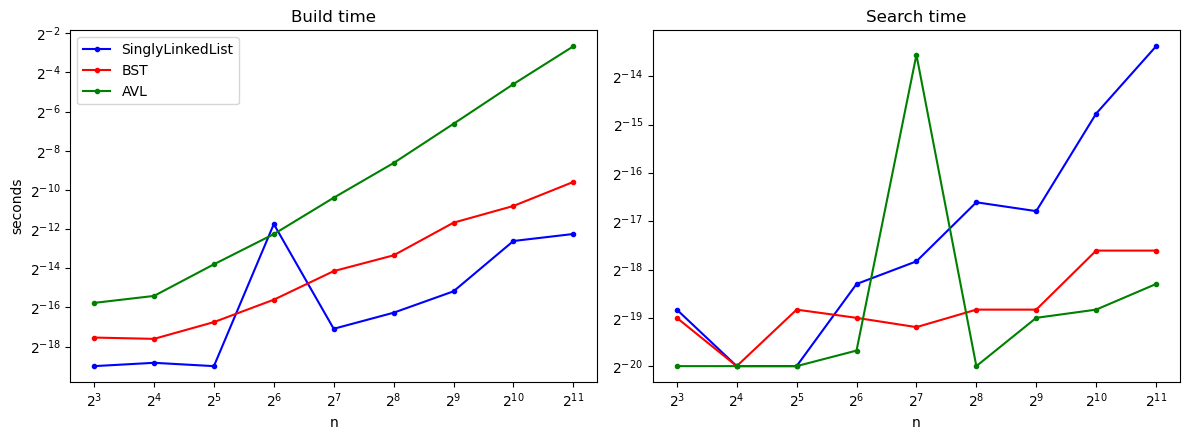

In [15]:
random.seed(0)          # prob4() samples with the random module
np.random.seed(0)
plt.figure(figsize=(12, 4.5))
prob4()
plt.tight_layout()
plt.show()

## Conclusion

Every data structure has advantages and disadvantages. Recognizing when an application may take advantage of a certain structure, especially when that structure is more complicated than a Python list or set, is an important skill. Choosing structures wisely often results in huge speedups and easier data maintenance.

## Additional Material

Ideas from the spec for extending this lab:

- **Improvements to the BST:** a constructor keyword argument that inserts each element of an iterable (casting an iterable as a BST); a size attribute behind a `__len__()` magic method; and a method that translates the BST into a sorted Python list with a depth-first search (examine the provided `__str__()` method).
- **B-Tree:** nodes can contain more than one piece of data and point to more than one other node (Chapter 2 of the Volume II text).
- **Red-Black Tree:** nodes are labeled red or black so that every leaf is black, red nodes only have black children, and every directed path from a node to any of its descendent leaves contains the same number of black nodes. When an added node violates a rule, the tree is rebalanced and recolored.
- **Splay Tree:** an additional *splaying* operation makes a specified node the root, so splayed nodes of interest are close to the root and easier to access.